<a href="https://colab.research.google.com/github/TejasDharmale/complex-adaptive-systems/blob/main/CAS_assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 4 - Stochastic Processes

Name: Tejas Dharmale

Student #: s1190137

In [1]:
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.random as jr

# Exercise 1: Wiener process (2 points)

Generate samples from a Wiener process and visualise the evolution of the density (confidence interval) over time. See slide 38 of the stochastic processes lecture for an example.

## Solution 1

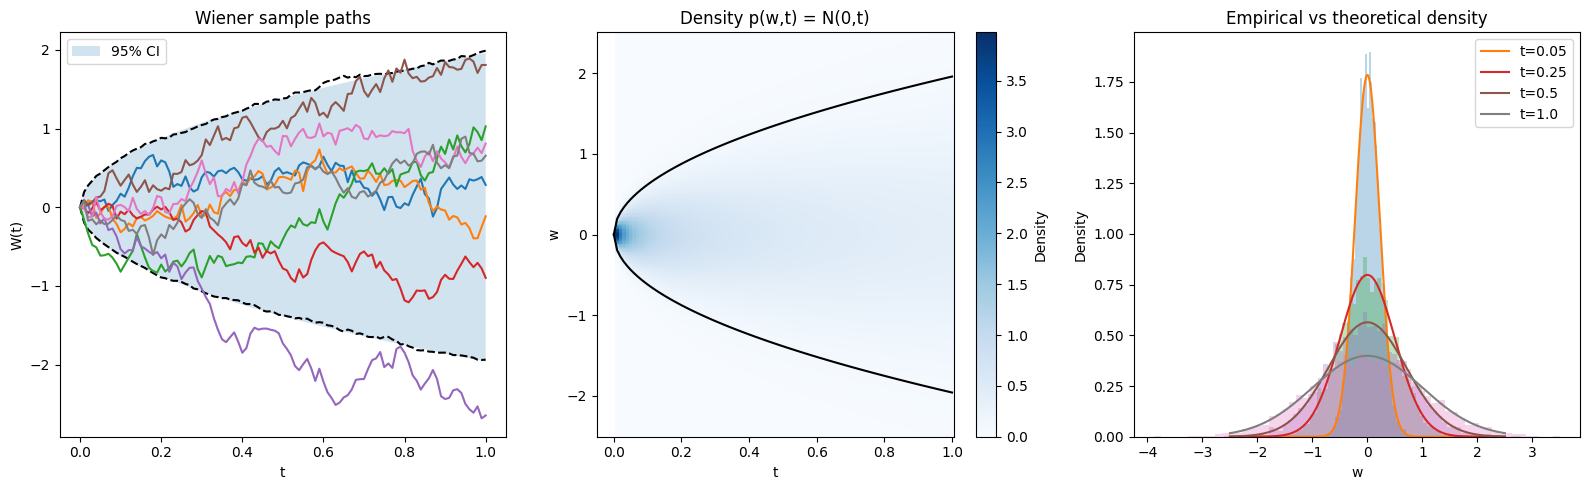

Max |mean|: 0.011396572925150394
Max |variance - t|: 0.01274716854095459
Final variance: 0.9974542260169983 Expected: 1.0


In [2]:
from jax.scipy.stats import norm

key = jax.random.PRNGKey(42)
T, N, S = 1.0, 100, 5000
dt = T / N
t = jnp.linspace(0, T, N + 1)


dW = jnp.sqrt(dt) * jax.random.normal(key, (S, N))
W = jnp.concatenate([jnp.zeros((S, 1)), jnp.cumsum(dW, axis=1)], axis=1)

ci = 1.96 * jnp.sqrt(t)
q_lo, q_hi = jnp.percentile(W, jnp.array([2.5, 97.5]), axis=0)
mean, var = W.mean(axis=0), W.var(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))


ax = axes[0]
ax.fill_between(t, -ci, ci, alpha=0.2, label="95% CI")
ax.plot(t, q_lo, "k--", t, q_hi, "k--")
for i in range(8):
    ax.plot(t, W[i])
ax.set(title="Wiener sample paths", xlabel="t", ylabel="W(t)")
ax.legend()


w = jnp.linspace(-2.5, 2.5, 300)
tt, ww = jnp.meshgrid(t[1:], w)
im = axes[1].pcolormesh(tt, ww, norm.pdf(ww, 0, jnp.sqrt(tt)),
                         shading="auto", cmap="Blues")
axes[1].plot(t, ci, "k-", t, -ci, "k-")
axes[1].set(title="Density p(w,t) = N(0,t)", xlabel="t", ylabel="w")
fig.colorbar(im, ax=axes[1], label="Density")


for ts in [0.05, 0.25, 0.5, 1.0]:
    idx = round(ts / dt)
    axes[2].hist(W[:, idx], bins=60, density=True, alpha=0.3)
    axes[2].plot(w, norm.pdf(w, 0, jnp.sqrt(t[idx])),
                 label=f"t={ts}")
axes[2].set(title="Empirical vs theoretical density",
            xlabel="w", ylabel="Density")
axes[2].legend()

fig.tight_layout()
fig.savefig("wiener_process_jax.png", dpi=150)
plt.show()

# Sanity checks
print("Max |mean|:", float(jnp.abs(mean).max()))
print("Max |variance - t|:", float(jnp.abs(var - t).max()))
print("Final variance:", float(var[-1]), "Expected:", T)


# Exercise 2: Compound Poisson process (3 points)

Simulate the compound Poisson process under different intensities. Compare the processes using a Gaussian and Exponential jump size distribution and describe the processes you find.

## Solution 2

jumps        lambda  mean J(T)  theory  var J(T)  theory
Gaussian        0.5      -0.01    0.00      5.14    5.00
Gaussian        2.0       0.12    0.00     19.31   20.00
Gaussian       10.0      -0.36    0.00     99.80  100.00
Exponential     0.5       4.99    5.00     10.04   10.00
Exponential     2.0      20.18   20.00     40.44   40.00
Exponential    10.0      99.77  100.00    199.82  200.00


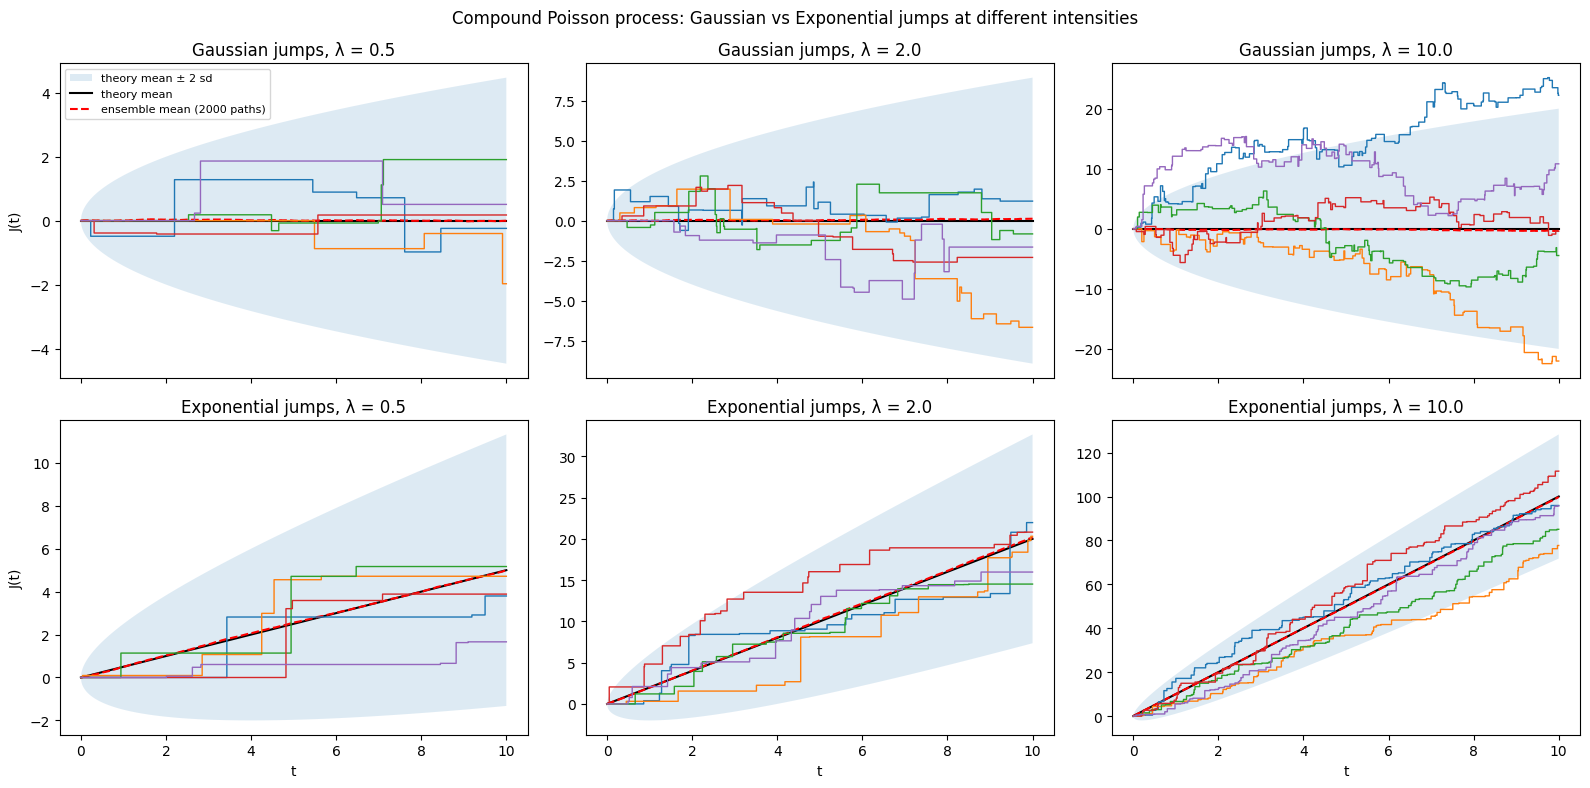

In [3]:
key = jr.PRNGKey(42)
T, N = 10.0, 1000
dt = T / N
t = jnp.linspace(0, T, N + 1)
lams = [0.5, 2.0, 10.0]       # intensities
S = 2000                      # ensemble size (for mean and spread)
n_show = 5                    # paths to plot


def compound_poisson(key, lam, dist, S):
    """Compound Poisson process on a grid.
    N_n ~ Poisson(lam*dt) events per step; the sum of N_n i.i.d. jumps is sampled exactly:
      Gaussian:    sum of N_n N(0,1) jumps   ~ sqrt(N_n) * N(0,1)
      Exponential: sum of N_n Exp(1) jumps   ~ Gamma(N_n, 1)  (0 if N_n = 0)
    """
    k1, k2 = jr.split(key)
    counts = jr.poisson(k1, lam * dt, (S, N))
    if dist == "Gaussian":
        dJ = jnp.sqrt(counts) * jr.normal(k2, (S, N))
    else:
        dJ = jnp.where(counts > 0, jr.gamma(k2, jnp.maximum(counts, 1).astype(float)), 0.0)
    return jnp.concatenate([jnp.zeros((S, 1)), jnp.cumsum(dJ, axis=1)], axis=1)


fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
print(f"{'jumps':12s}{'lambda':>7s}{'mean J(T)':>11s}{'theory':>8s}{'var J(T)':>10s}{'theory':>8s}")

for row, dist in enumerate(["Gaussian", "Exponential"]):
    EZ, EZ2 = (0.0, 1.0) if dist == "Gaussian" else (1.0, 2.0)
    for col, lam in enumerate(lams):
        key, sub = jr.split(key)
        J = compound_poisson(sub, lam, dist, S)
        ax = axes[row, col]

        # theoretical mean and +- 2 sd band:  E[J] = lam t E[Z],  Var[J] = lam t E[Z^2]
        m, sd = lam * t * EZ, jnp.sqrt(lam * t * EZ2)
        ax.fill_between(t, m - 2 * sd, m + 2 * sd, alpha=0.15, label="theory mean ± 2 sd")
        ax.plot(t, m, "k-", label="theory mean")
        ax.plot(t, J.mean(axis=0), "r--", label=f"ensemble mean ({S} paths)")
        for i in range(n_show):
            ax.step(t, J[i], where="post", lw=1)

        ax.set(title=f"{dist} jumps, λ = {lam}")
        if col == 0:
            ax.set_ylabel("J(t)")
        if row == 1:
            ax.set_xlabel("t")

        print(f"{dist:12s}{lam:7.1f}{float(J[:, -1].mean()):11.2f}{float(m[-1]):8.2f}"
              f"{float(J[:, -1].var()):10.2f}{float(sd[-1]**2):8.2f}")

axes[0, 0].legend(fontsize=8, loc="upper left")
fig.suptitle("Compound Poisson process: Gaussian vs Exponential jumps at different intensities")
fig.tight_layout()
plt.show()

In [4]:
# The compound Poisson process $J(t)$ is piecewise constant: constant on intervals between the events, with jumps at Poisson moments (on average $1/\lambda$ apart). In general, $\mathbb{E}[J(t)] = \lambda t\,\mathbb{E}[Z]$ and $\mathrm{Var}[J(t)] = \lambda t\,\mathbb{E}[Z^2]$, which simulations verify.

# Intensity λ: small λ leads to sparse and clearly seen jumps, while large λ leads to densely packed jumps that almost look continuous, together with larger variance.
# Gaussian jumps: the jumps have positive and negative values, so there is no drift ($\mathbb{E}[J]=0$, $\mathrm{Var}=\lambda t$).
# Exponential jumps: all the jumps are positive, therefore the paths are nondecreasing with drift $\lambda t$ and variance $2\lambda t$.

# In case of large λ, numerous small jumps make the process $J(t)$ behave approximately Gaussian (central limit theorem), thus leading to diffusion processes.

# Exercise 3: Jump-diffusion process (5 points)

Simulate a stochastic harmonic oscillator, where the velocity is subjected to both a **Wiener process** and **jump processes**. Use a Gaussian jump distribution in the jump process. Choose the parameters such that the noise is visible but does not completely dominate the dynamics.

Generate an ensemble of trajectories. Plot a couple of trajectories of this ensemble and plot the confidence interval of the whole ensemble. Explain what happens with the confidence interval when you increase the number of samples in your ensemble.

## Solution 3

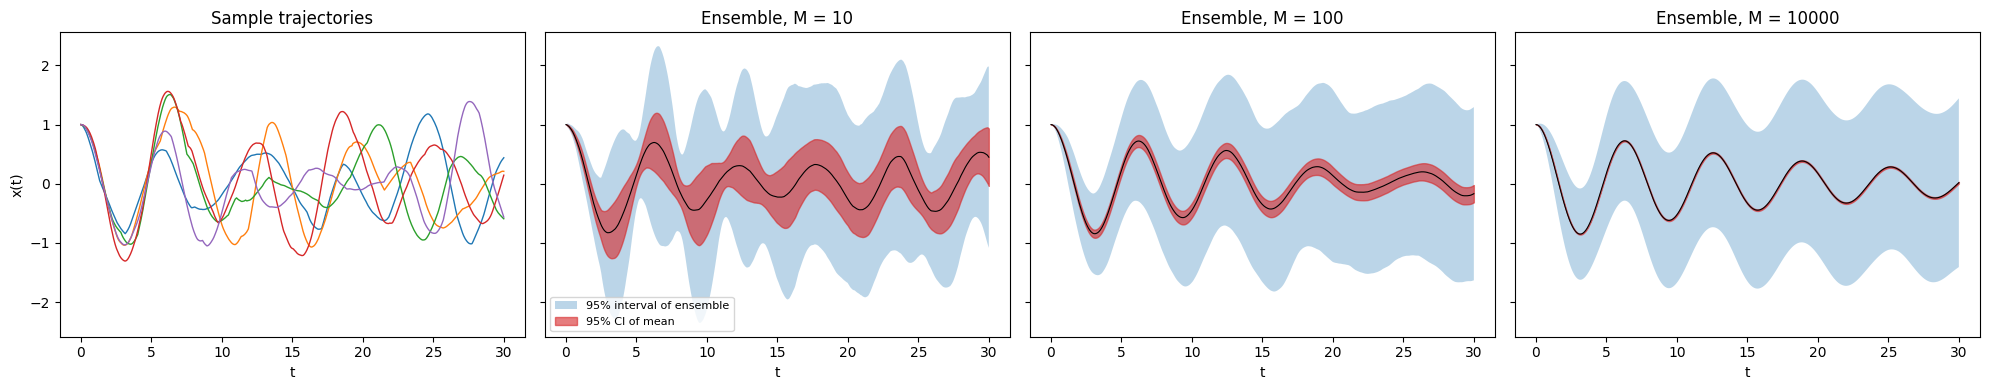

In [5]:
T, N = 30.0, 3000
dt = T / N
t = jnp.linspace(0, T, N + 1)
omega, gamma, sigma, lam, jump_sigma = 1.0, 0.1, 0.15, 1.0, 0.3


def simulate(key, M):
    """dv = (-omega^2 x - gamma v) dt + sigma dW + dJ,  dx = v dt  (semi-implicit Euler)"""
    k1, k2, k3 = jr.split(key, 3)
    dW = jnp.sqrt(dt) * jr.normal(k1, (N, M))
    dJ = jump_sigma * jnp.sqrt(jr.poisson(k2, lam * dt, (N, M))) * jr.normal(k3, (N, M))

    def step(state, inp):
        x, v = state
        v = v + (-omega**2 * x - gamma * v) * dt + sigma * inp[0] + inp[1]
        x = x + v * dt
        return (x, v), x

    _, xs = jax.lax.scan(step, (jnp.ones(M), jnp.zeros(M)), (dW, dJ))
    return jnp.vstack([jnp.ones((1, M)), xs]).T   # shape (M, N+1)


fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
X = simulate(jr.PRNGKey(0), 5)
for x in X:
    axes[0].plot(t, x, lw=1)
axes[0].set(title="Sample trajectories", xlabel="t", ylabel="x(t)")

for ax, M in zip(axes[1:], [10, 100, 10000]):
    X = simulate(jr.PRNGKey(M), M)
    m, s = X.mean(0), X.std(0)
    ax.fill_between(t, m - 1.96 * s, m + 1.96 * s, alpha=0.3, label="95% interval of ensemble")
    ax.fill_between(t, m - 1.96 * s / M**0.5, m + 1.96 * s / M**0.5, color="C3",
                    alpha=0.6, label="95% CI of mean")
    ax.plot(t, m, "k", lw=0.8)
    ax.set(title=f"Ensemble, M = {M}", xlabel="t")
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

In [6]:
# Observations

# Velocity experiences continuous kicks due to the Wiener process and Gaussian jumps at random times.
# For γ = 0.1 there is noise, but it is not overwhelming: the trajectories fluctuate around the noiseless damped oscillation, while the mean trajectory sticks close to it.
# First the spread increases and then it reaches the constant level because of the damping which absorbs the energy provided by the noise.

# Effect of the ensemble size M.The interval of the 95% probability of the trajectories (mean ± 1.96 std) does not become narrower with increasing number of samples.
# This interval reflects the variability of the process itself, therefore for bigger M it gets smoother and approaches its exact width (std at t = T equals to approximately 0.73 for every M).
# However, the interval of the mean trajectory (± 1.96 std/√M) decreases with $1/\sqrt{M}$( half-width 0.49, 0.15, 0.04, 0.01 for M = 10, 100, 1000, 10000).